In [3]:
import numpy as np

# 假设 bs 和 B 的值
bs = 1
B =1
size = 8
bit_size = 3

vector1 = np.random.rand(bs, 2, B, size, size, 5)
vector2 = np.random.randint(-2**(bit_size-1)+1, 2**(bit_size-1), size=(bs, 2, B, size, size, 5))
vector3 = np.zeros((bs, size, size, 2**bit_size))

# 广播和高级索引
vector1_transposed = np.transpose(vector1, (0, 3, 4, 1, 2, 5))
vector2_transposed = np.transpose(vector2, (0, 3, 4, 1, 2, 5))
print(vector1.shape, " to ", vector1_transposed.shape)
print(vector2.shape, " to ", vector2_transposed.shape)

vector1_reshaped = vector1_transposed.reshape(bs, size, size, -1)
vector2_reshaped = vector2_transposed.reshape(bs, size, size, -1)
print(vector1_transposed.shape, " to ", vector1_reshaped.shape)
print(vector2_transposed.shape, " to ", vector2_reshaped.shape)

# 将 vector2 的索引值调整为非负
vector2_reshaped = vector2_reshaped + 2**(bit_size-1)-1

np.add.at(vector3, (np.arange(bs)[:, None, None, None], np.arange(size)[None, :, None, None], np.arange(size)[None, None, :, None], vector2_reshaped), vector1_reshaped)
print(vector1_reshaped[0,0,1,:])
print(vector2_reshaped[0,0,1,:])
print(vector3[0,0,1,:])

(1, 2, 1, 8, 8, 5)  to  (1, 8, 8, 2, 1, 5)
(1, 2, 1, 8, 8, 5)  to  (1, 8, 8, 2, 1, 5)
(1, 8, 8, 2, 1, 5)  to  (1, 8, 8, 10)
(1, 8, 8, 2, 1, 5)  to  (1, 8, 8, 10)
[0.54968092 0.85263745 0.37725468 0.13756578 0.08002029 0.49297515
 0.39173948 0.74041119 0.10728626 0.07341904]
[3 1 0 5 4 0 2 4 5 1]
[0.87022983 0.92605649 0.39173948 0.54968092 0.82043148 0.24485204
 0.         0.        ]


In [48]:
import numpy as np

def diagonal_sum(a, b):
    a = np.array(a)
    b = np.array(b)
    
    n = len(a)
    
    P = np.outer(a, b)
    print(P)
    
    diagonals_sum = [np.sum(np.diag(P, k)) for k in range(-n+1, n)]
    
    return diagonals_sum

a = [0.1, 0.2, 0.3, 0.4, 0.5]
b = [0.5, 0.4, 0.3, 0.2, 0.1]

result = diagonal_sum(a, b)
print("Total diagonal sum:", result)
print("numpy.convolve:",np.convolve(a[::-1], b, mode='full'))

[[0.05 0.04 0.03 0.02 0.01]
 [0.1  0.08 0.06 0.04 0.02]
 [0.15 0.12 0.09 0.06 0.03]
 [0.2  0.16 0.12 0.08 0.04]
 [0.25 0.2  0.15 0.1  0.05]]
Total diagonal sum: [0.25, 0.4, 0.4600000000000001, 0.43999999999999995, 0.35000000000000003, 0.2, 0.1, 0.04000000000000001, 0.010000000000000002]
numpy.convolve: [0.25 0.4  0.46 0.44 0.35 0.2  0.1  0.04 0.01]


In [38]:
import numpy as np

def diagonal_sum_1(a, b):
    a = np.array(a)
    b = np.array(b)
    
    n = len(a)
    
    diagonals_sum = []
    for k in range(-n + 1, n):
        diagonals_sum.append(np.sum(a[max(0, -k):n - max(0, k)] * b[max(0, k):n - max(0, -k)]))
    
    return diagonals_sum

a = [0.1, 0.2, 0.3, 0.4, 0.5]
b = [0.5, 0.4, 0.3, 0.2, 0.1]

result = diagonal_sum_1(a, b)
print("Total diagonal sum:", result)
print("numpy.convolve:",np.convolve(a, b))

Total diagonal sum: [0.25, 0.4, 0.4600000000000001, 0.43999999999999995, 0.35000000000000003, 0.2, 0.1, 0.04000000000000001, 0.010000000000000002]
numpy.convolve: [0.05 0.14 0.26 0.4  0.55 0.4  0.26 0.14 0.05]


In [74]:
import numpy as np
import torch
import torchaudio
import torchaudio.functional as F

def diagonal_sum_2(a, b):
    a = np.array(a)
    b = np.array(b)
    
    bs, ch, B, n = a.shape
    result_shape = (bs, ch, B, 2 * n - 1)
    diagonals_sum = np.zeros(result_shape)
    
    for b_idx in range(B):
        for k in range(-n + 1, n):
            diag_sum = np.sum(
                a[:, :, b_idx, max(0, -k):n - max(0, k)] *
                b[:, :, b_idx, max(0, k):n - max(0, -k)],
                axis=-1
            )
            diagonals_sum[:, :, b_idx, k + n - 1] = diag_sum
    
    return diagonals_sum

# Example usage
a = np.random.rand(2, 3, 4, 5)
b = np.random.rand(2, 3, 4, 5)
result = diagonal_sum_2(a, b)

print("ab:", diagonal_sum_1(a[0,0,0,:], b[0,0,0,:]))
print("results[0,0,0,:]:", result[0,0,0,:])
print("results shape:", result.shape)  # Should print (2, 3, 4, 9)
# print("results",result)

a_tensor = torch.from_numpy(a[:,:,:,::-1].copy()).double()
b_tensor = torch.from_numpy(b).double()

convolved_tensor = F.convolve(a_tensor, b_tensor)
print("results shape:", convolved_tensor.shape)
print("convolved_tensor:", convolved_tensor[0,0,0,:])

ab: [0.20263990254985909, 0.7086499033244426, 1.0685464233337578, 1.4127325309523253, 1.8874676764828258, 1.5536695505499587, 1.0334567577384919, 0.8984417314934039, 0.3193103611626825]
results[0,0,0,:]: [0.2026399  0.7086499  1.06854642 1.41273253 1.88746768 1.55366955
 1.03345676 0.89844173 0.31931036]
results shape: (2, 3, 4, 9)
results shape: torch.Size([2, 3, 4, 9])
convolved_tensor: tensor([0.20263990, 0.70864990, 1.06854642, 1.41273253, 1.88746768, 1.55366955,
        1.03345676, 0.89844173, 0.31931036], dtype=torch.float64)


In [35]:
import numpy as np

def diagonal_sum(a, b):
    a = np.array(a)
    b = np.array(b)
    
    bs, ch, B, n = a.shape
    result_shape = (bs, ch, B, 2 * n - 1)
    
    # Apply convolution along the last axis using broadcasting
    diagonals_sum = np.apply_along_axis(
        lambda x: np.convolve(x[0], x[1], mode='full'), 
        -1, 
        np.stack((a, b), axis=-1)
    )
    
    return diagonals_sum

# Example usage
a = np.random.rand(2, 3, 4, 5)
b = np.random.rand(2, 3, 4, 5)
result = diagonal_sum(a, b)
print(result.shape)  # Should print (2, 3, 4, 9)


(2, 3, 4, 5, 1)


In [73]:
a = np.random.rand(5)
b = torch.from_numpy(a)
print("a",a)
torch.set_printoptions(profile="full")
torch.set_printoptions(threshold=float('inf'), precision=8)
print("b",b)

a [0.64867891 0.47492326 0.26037906 0.39767643 0.56810437]
b tensor([0.64867891, 0.47492326, 0.26037906, 0.39767643, 0.56810437],
       dtype=torch.float64)


In [37]:
# 假设你的张量是一个 NumPy 数组
tensor = np.random.randint(0, 10,(1, 2, 3, 5))
# 将B轴右移一位
shifted_tensor = np.roll(tensor, shift=1, axis=2)
shifted_tensor[:,:,0,:] = [1,0,0,0,0]

print(tensor)
print(shifted_tensor)

[[[[7 6 6 6 1]
   [0 5 5 2 1]
   [9 1 1 3 6]]

  [[3 4 2 0 5]
   [4 3 3 1 4]
   [5 1 8 8 0]]]]
[[[[1 0 0 0 0]
   [7 6 6 6 1]
   [0 5 5 2 1]]

  [[1 0 0 0 0]
   [3 4 2 0 5]
   [4 3 3 1 4]]]]


In [13]:
import numpy as np
# 创建两个形状为 (2, 3, 4, 5) 的示例向量
vector1 = torch.randint(0, 10, (2,3,4,5))
vector2 = torch.randint(0, 10, (2,3,4,5))

def get_diff_indexes(indexes, indexes_shifted):
    middle = indexes[:,:,:,0] - indexes_shifted[:,:,:,0] # shape: [bs,ch,B]
    diff_indexes = middle.unsqueeze(-1) # shape: [bs,ch,B,1]
    diff_indexes = diff_indexes.expand(-1, -1, -1, 2*5-1) + np.arange(-5 + 1,5) # shape: [bs,ch,B,9]
    return diff_indexes

print(get_diff_indexes(vector1,vector2).shape)

torch.Size([2, 3, 4, 9])


In [14]:
import torch
import torchaudio
import torchaudio.functional as F

# 定义两个vector A和B
a = torch.randint(0, 10, (5,))
b = torch.randint(0, 10, (5,))

c = F.convolve(a,b)
print(a)
print(b)
print(c)

tensor([7, 6, 9, 9, 7])
tensor([8, 3, 7, 7, 7])
tensor([ 56,  69, 139, 190, 237, 189, 175, 112,  49])


In [7]:
import torch 
from torch.special import entr

def calculate_entropy(tensor):
    # Calculate entropy
    entropy = -torch.sum(tensor * torch.log(tensor + 1e-10), dim=-1)  # Add a small value to avoid log(0)
    
    return entropy

# Example usage
bs = 2
size = 3
num_bit = 2
tensor = torch.rand(bs, size, size, 2**num_bit - 1)
# Ensure tensor values are probabilities
tensor = torch.softmax(tensor, dim=-1)

entropy = calculate_entropy(tensor)
entropy_2 = entr(tensor)
print(entropy)
print(-torch.sum(entropy_2,dim=-1))


tensor([[[1.0236, 1.0972, 1.0661],
         [1.0968, 1.0864, 1.0603],
         [1.0569, 1.0660, 1.0645]],

        [[1.0850, 1.0755, 1.0678],
         [1.0500, 1.0614, 1.0972],
         [1.0629, 1.0737, 1.0713]]])
tensor([[[-1.0236, -1.0972, -1.0661],
         [-1.0968, -1.0864, -1.0603],
         [-1.0569, -1.0660, -1.0645]],

        [[-1.0850, -1.0755, -1.0678],
         [-1.0500, -1.0614, -1.0972],
         [-1.0629, -1.0737, -1.0713]]])


[ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30. 31. 32. 33. 34. 35.
 36. 37. 38. 39. 40. 41. 42. 43. 44. 45. 46. 47. 48. 49. 50. 51. 52. 53.
 54. 55. 56. 57. 58. 59. 60. 61. 62. 63.]


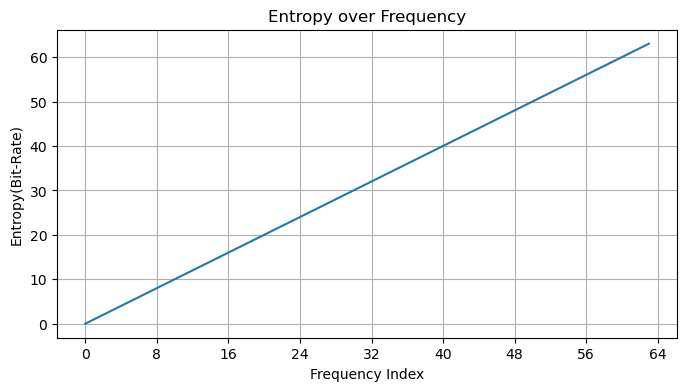

In [9]:
import matplotlib.pyplot as plt
import numpy as np

def zigzag(matrix):
    zigzag = np.array([[0, 1, 5, 6, 14, 15, 27, 28],
                           [2, 4, 7, 13, 16, 26, 29, 42],
                           [3, 8, 12, 17, 25, 30, 41, 43],
                           [9, 11, 18, 24, 31, 40, 44, 53],
                           [10, 19, 23, 32, 39, 45, 52, 54],
                           [20, 22, 33, 38, 46, 51, 55, 60],
                           [21, 34, 37, 47, 50, 56, 59, 61],
                           [35, 36, 48, 49, 57, 58, 62, 63]])

    # Get the shape of the matrix
    matrix_size = np.shape(matrix)

    # Calculate the size of the vector
    vector_size = np.shape(zigzag)

    # Check if the matrix size matches the vector size
    if matrix_size != vector_size:
        raise ValueError("The matrix size does not match the vector size.")

    # Create an empty vector to store the values
    vector = np.zeros(matrix_size[0] * matrix_size[1])

    # Iterate over each element in the matrix and place it in the corresponding position in the vector
    for i in range(matrix_size[0]):
        for j in range(matrix_size[1]):
            index = zigzag[i, j]
            vector[index] = matrix[i, j]

    return vector

def visualize_entropy(entropy):
    mean_entropy = entropy.mean(axis=0)
    flattened_entropy = zigzag(mean_entropy).flatten()
    print(flattened_entropy)
    
    # 可视化结果
    plt.figure(figsize=(8, 4))
    plt.plot(flattened_entropy)
    plt.title("Entropy over Frequency")
    plt.xlabel("Frequency Index")
    plt.ylabel("Entropy(Bit-Rate)")
    plt.xticks(np.arange(0, len(flattened_entropy)+1, 8))
    plt.grid(True)
    plt.show()

a = np.array([[[0,  1,  5,  6,  14, 15, 27, 28],
                [2,  4,  7,  13, 16, 26, 29, 42],
                [3,  8,  12, 17, 25, 30, 41, 43],
                [9,  11, 18, 24, 31, 40, 44, 53],
                [10, 19, 23, 32, 39, 45, 52, 54],
                [20, 22, 33, 38, 46, 51, 55, 60],
                [21, 34, 37, 47, 50, 56, 59, 61],
                [35, 36, 48, 49, 57, 58, 62, 63]]])
visualize_entropy(a)